# Does the mtDSB oligodendrocyte signature appear in human MS?

The mtDSB OL response is an ATF4 / ISR programme with mtDSB-specific markers (Trib3, Gdf15, Atf5, Eif4ebp1) plus a
p53 / p21 arm, and no interferon-gamma response; EAE OLs show the reverse (analysis/10, /13). Here the same gene sets,
as human orthologs (`utils/human_ms.py`), are scored in oligodendrocyte nuclei of four human MS single-nucleus atlases
(harmonised copies on the office Mac, `/Volumes/jamboree/OligoC4b_public/processed`):

| dataset | tissue | lesion types |
|---|---|---|
| Jäkel 2019 | white matter | active (A), chronic active (CA), chronic inactive (CI), remyelinating (RM), NAWM |
| Schirmer 2019 | cortex + subcortical WM | acute / chronic active, chronic inactive |
| Absinta 2021 | white matter | chronic active and inactive lesion edges, periplaque WM, lesion core |
| Lerma-Martin 2024 | subcortical WM | chronic active (CA), chronic inactive (CI) |

* **A.** Pathway scores per sample (pseudobulk), lesion types vs controls, next to mtDSB and EAE.
* **B.** The mtDSB core genes one by one.
* **C.** Per cell: is there a rare subpopulation of OLs carrying the mtDSB-specific markers? Lerma-Martin OL subtypes.
* **D.** Genome-wide similarity of the MS OL response to mtDSB and to EAE.

Inputs: `results/human_ms/human_ol_*.csv*` (`scripts/export_human_ms_ol.py`, office Mac), analysis/10 tables.
Caveats up front: single-nucleus RNA (nuclear transcripts, low depth), post-mortem human tissue with variable
PMI / RIN, few samples per lesion type, and no matched time point.

In [1]:
import sys
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
REPO = Path.cwd().resolve().parent; sys.path.insert(0, str(REPO))
from utils import composition as co
from utils.human_ms import gene_sets, to_human

OUT = REPO / "results" / "human_ms"; FIG = OUT / "figures"; TAB = OUT / "tables"
FIG.mkdir(parents=True, exist_ok=True); TAB.mkdir(parents=True, exist_ok=True)
SETS = gene_sets(REPO)
meta = pd.read_csv(OUT / "human_ol_pseudobulk_meta.csv", index_col=0)
pb = pd.read_csv(OUT / "human_ol_pseudobulk.csv.gz", index_col=0)
cells = pd.read_csv(OUT / "human_ol_cells.csv.gz")
CORE = [g for g in SETS["MTDSB_CORE"] if g in cells]
SPECIFIC = ["TRIB3", "GDF15", "ATF5", "EIF4EBP1"]          # mtDSB-specific vs EAE (analysis/10)
CTRL = {"Jakel2019": "Ctrl", "Schirmer2019": "Control", "Absinta2021": "control_white_matter", "LermaMartin2024": "Ctrl"}
LES_ORDER = {"Jakel2019": ["NAWM", "A", "CA", "CI", "RM"], "Schirmer2019": ["Acute/Chronic active", "Chronic inactive"],
             "Absinta2021": ["MS_periplaque_white_matter", "chronic_active_MS_lesion_edge", "chronic_inactive_MS_lesion_edge"],
             "LermaMartin2024": ["CA", "CI"]}
SHORT = {"MS_periplaque_white_matter": "periplaque", "chronic_active_MS_lesion_edge": "CA edge", "chronic_inactive_MS_lesion_edge": "CI edge",
         "Acute/Chronic active": "A/CA", "Chronic inactive": "CI"}
MIN_NUCLEI = 30

INK2, AXIS = "#52514e", "#c3c2b7"
BLUE, ORANGE, GREY = "#2a78d6", "#eb6834", "#b8b7b0"
plt.rcParams.update({"axes.edgecolor": AXIS, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
                     "axes.spines.top": False, "axes.spines.right": False, "font.size": 9, "axes.titlelocation": "left"})
def save(fig, name, dpi=200):
    fig.savefig(FIG / f"{name}.png", dpi=dpi, bbox_inches="tight"); fig.savefig(FIG / f"{name}.pdf", bbox_inches="tight")
def save_table(df, name, index=True):
    df.to_csv(TAB / f"{name}.csv", index=index); return df
ol = cells[cells.cell_type == "Oligodendrocyte"]
display(cells.groupby(["dataset", "lesion", "cell_type"]).size().unstack(fill_value=0))

cell_type                                         OPC  Oligodendrocyte
dataset         lesion                                                
Absinta2021     MS_lesion_core                    132               19
                MS_periplaque_white_matter        645            17563
                chronic_active_MS_lesion_edge     567            12658
                chronic_inactive_MS_lesion_edge   536            11193
                control_white_matter              295             4264
Jakel2019       A                                  17             1102
                CA                                 13              435
                CI                                 23             1068
                Ctrl                              273             3530
                NAWM                               25             1478
                RM                                  1              360
LermaMartin2024 CA                               1978            27370
                CI                                712            15968
                Ctrl                             1255            21495
Schirmer2019    Acute/Chronic active             1776             8266
                Chronic inactive                  894             1058
                Control                          1174             3070

## A. Pathway scores per sample

,mtDSB responders,EAE lesion,EAE normal-appearing,DAO vs MOL,n_genes
ATF4 / integrated stress response,1.85,0.06,-0.15,0.06,8
cell cycle / survival,2.52,0.67,-0.02,0.83,4
immune / reactive,2.25,2.41,1.13,0.94,5
mitochondrial & protein quality control,0.69,0.28,0.10,0.07,6
mature OL / myelin (down),-0.62,-0.22,-0.23,-0.00,9
"ISR (prespecified, 10 genes)",1.83,0.21,-0.02,0.02,6
MHC class I,0.83,3.27,2.26,0.65,4
interferon (type I),0.19,1.27,0.22,0.84,2
"IFN-gamma (Irf1, Gbp, Irgm, Psmb8/9, Cxcl9/10, Stat1)",0.32,3.11,1.72,1.00,6
myelin (prespecified),-0.49,-0.15,-0.37,0.23,13


,Jakel NAWM,Jakel A,Jakel CA,Jakel CI,Jakel RM,Schirmer A/CA,Schirmer CI,Absinta periplaque,Absinta CA edge,Absinta CI edge,LermaMartin CA,LermaMartin CI
gene_set,,,,,,,,,,,,
MTDSB_CORE,0.43,0.43,-0.92,-1.28,0.15,0.91,1.17,0.69,1.04,0.82,1.16,0.82
ISR,0.20,0.20,-0.82,-1.62,-0.20,0.84,0.86,0.25,0.44,0.49,1.00,0.88
P53,0.36,0.38,-0.74,-0.87,0.70,0.43,0.86,0.47,0.78,0.62,0.53,0.56
DRIVERS_UP,0.16,0.18,0.02,-1.16,0.28,0.93,0.93,0.30,0.73,0.67,1.00,0.89
IFNG,1.29,1.06,2.75,-0.44,1.12,1.31,0.20,0.96,1.91,1.27,1.76,1.87
IMMUNE_OL,0.52,0.88,-0.25,-0.65,-0.46,1.64,1.67,0.94,2.08,1.92,1.82,2.18
MYELIN,0.03,0.17,0.04,-1.28,-0.15,0.16,-0.34,-0.61,-0.65,-0.14,-0.05,-0.12
DRIVERS_DOWN,0.30,0.63,0.50,-0.07,0.30,0.13,0.07,-0.60,-0.36,0.23,0.30,0.36


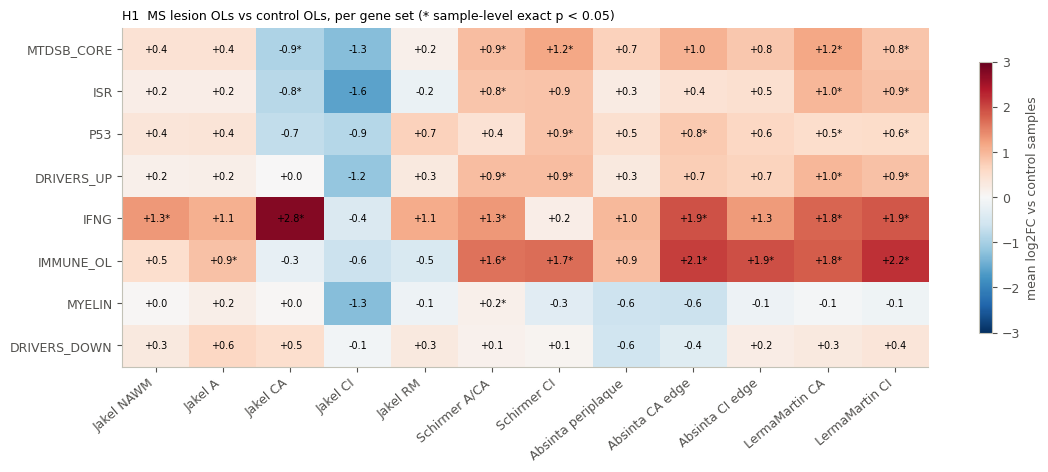

In [2]:
def sample_log_cpm(ds):
    # per (sample, lesion) OL pseudobulk: panel genes from the pseudobulk table, core genes from the per-cell counts
    m = meta[(meta.dataset == ds) & (meta.cell_type == "Oligodendrocyte") & (meta.n_cells >= MIN_NUCLEI)]
    P = pb.loc[m.index].set_index(pd.MultiIndex.from_frame(m[["sample", "lesion"]]))
    d = ol[ol.dataset == ds]; g = d.groupby(["sample", "lesion"])
    tot = g.total_counts.sum().reindex(P.index)
    core = g[CORE].sum().reindex(P.index)
    P = P.drop(columns=[c for c in CORE if c in P]).join(core)
    cpm = P.div(tot, axis=0) * 1e6
    return np.log2(cpm + 1)
rows, per_sample = [], []
for ds, ctl in CTRL.items():
    L = sample_log_cpm(ds)
    expressed = L.columns[(np.exp2(L) - 1).mean() > 1]
    Z = L[expressed] - L[expressed].xs(ctl, level="lesion").mean()
    for s, genes in SETS.items():
        g = [x for x in genes if x in Z]
        sc = Z[g].mean(1)
        per_sample.append(sc.rename("score").reset_index().assign(dataset=ds, gene_set=s))
        for les in LES_ORDER[ds]:
            if les not in sc.index.get_level_values("lesion"): continue
            a = sc.xs(les, level="lesion"); b = sc.xs(ctl, level="lesion")
            v = pd.concat([a.rename(lambda x: f"L_{x}"), b.rename(lambda x: f"C_{x}")])
            _, p = co.exact_perm(v, [f"L_{x}" for x in a.index], [f"C_{x}" for x in b.index])
            rows.append({"dataset": ds, "lesion": SHORT.get(les, les), "gene_set": s, "n_genes": len(g), "n_lesion": len(a), "n_ctrl": len(b),
                         "log2fc": a.mean(), "ctrl_sd": b.std(), "p": p})
ps = save_table(pd.DataFrame(rows).round(4), "pathway_scores_lesion_vs_control", index=False)
save_table(pd.concat(per_sample).round(4), "pathway_scores_per_sample", index=False)

# mouse references (analysis/10 programme table: OL log2FC)
prog = pd.read_csv(REPO / "results" / "eae_comparison" / "tables" / "programme_log2fc.csv", index_col=0)
display(prog)
SHOWSETS = ["MTDSB_CORE", "ISR", "P53", "DRIVERS_UP", "IFNG", "IMMUNE_OL", "MYELIN", "DRIVERS_DOWN"]
cols = [(ds, SHORT.get(l, l)) for ds in CTRL for l in LES_ORDER[ds] if ((ps.dataset == ds) & (ps.lesion == SHORT.get(l, l))).any()]
H = pd.DataFrame({f"{ds[:-4]} {l}": ps[(ps.dataset == ds) & (ps.lesion == l)].set_index("gene_set").log2fc for ds, l in cols}).loc[SHOWSETS]
Pm = pd.DataFrame({f"{ds[:-4]} {l}": ps[(ps.dataset == ds) & (ps.lesion == l)].set_index("gene_set").p for ds, l in cols}).loc[SHOWSETS]
fig, ax = plt.subplots(figsize=(13, 4.4))
im = ax.imshow(H, cmap="RdBu_r", vmin=-3, vmax=3, aspect="auto")
for i in range(H.shape[0]):
    for j in range(H.shape[1]):
        ax.text(j, i, f"{H.iat[i, j]:+.1f}" + ("*" if Pm.iat[i, j] < 0.05 else ""), ha="center", va="center", fontsize=7)
ax.set_xticks(range(H.shape[1]), H.columns, rotation=40, ha="right"); ax.set_yticks(range(len(SHOWSETS)), SHOWSETS)
fig.colorbar(im, ax=ax, shrink=0.8, label="mean log2FC vs control samples")
ax.set_title("H1  MS lesion OLs vs control OLs, per gene set (* sample-level exact p < 0.05)", fontsize=9)
save(fig, "H1_pathway_heatmap")
display(H.round(2))

**A.** Three of the four atlases (Schirmer, Absinta, Lerma-Martin) agree: OLs in and around MS lesions raise the
**mtDSB core set by ~0.7-1.2 log2, the ISR set by ~0.25-1.0 and p53 targets by ~0.4-0.9**, while the **immune-visible
OL programme (~0.9-2.2) and interferon-gamma genes (up to ~1.9) rise as much or more** (mtDSB: core / ISR +1.8,
IFN-gamma +0.3; EAE: ISR +0.2, IFN-gamma +3.1). Periplaque white matter (Absinta) already shows part of it. Jäkel 2019
(few samples, shallow libraries) is inconsistent and the least reliable. Whether the core and ISR scores reflect the
mtDSB-specific part of the response is the question of B: both sets mix mtDSB-specific genes with general stress genes.

## B. The mtDSB core genes one by one

,TRIB3,GDF15,ATF5,EIF4EBP1,ALDH1L2,DDIT3,SESN2,CDKN1A,BBC3,GADD45A,ATF4,CEBPG,IRF1,PSMB8,SERPINA3,CD74
mtDSB responders (mouse),5.41,4.26,2.07,2.97,1.92,1.22,1.83,3.97,2.12,1.66,0.90,1.36,0.40,0.56,2.87,1.76
EAE lesion (mouse),0.75,NaN,0.62,NaN,NaN,0.09,0.12,0.03,NaN,0.41,0.10,-0.06,3.56,3.79,4.73,4.04
Jakel NAWM,-0.49,0.00,-0.29,0.01,0.66,-0.22,0.51,1.18,1.16,1.33,0.75,1.16,1.31,1.25,0.00,1.03
Jakel A,0.42,0.91,0.34,0.28,1.46,-0.96,0.21,1.31,0.39,1.83,0.27,0.70,-0.23,1.38,0.00,1.74
Jakel CA,-0.49,0.00,-3.27,-0.76,-0.71,-1.45,0.65,0.29,-1.18,0.11,0.41,0.59,2.69,2.46,0.00,1.57
Jakel CI,-0.00,0.00,-1.71,-0.27,-0.76,-3.38,-1.19,-1.23,-0.41,-1.44,0.38,-1.77,-0.76,-0.33,0.00,-1.55
Jakel RM,-0.49,0.00,-0.77,-0.76,-2.53,-0.44,2.61,0.78,2.18,2.46,1.44,2.10,2.45,-1.97,0.00,-0.54
Schirmer A/CA,0.85,0.15,0.90,0.54,1.67,1.41,1.55,0.80,0.35,1.17,0.47,0.53,1.12,1.31,0.41,1.78
Schirmer CI,1.14,0.84,1.32,0.05,-0.60,1.27,1.72,3.07,1.68,2.32,0.95,0.44,0.53,-0.31,-0.32,3.05
Absinta periplaque,-0.10,-0.04,-0.56,-0.22,0.00,0.96,1.31,1.76,0.15,1.13,-0.01,0.61,1.21,0.49,0.00,0.16


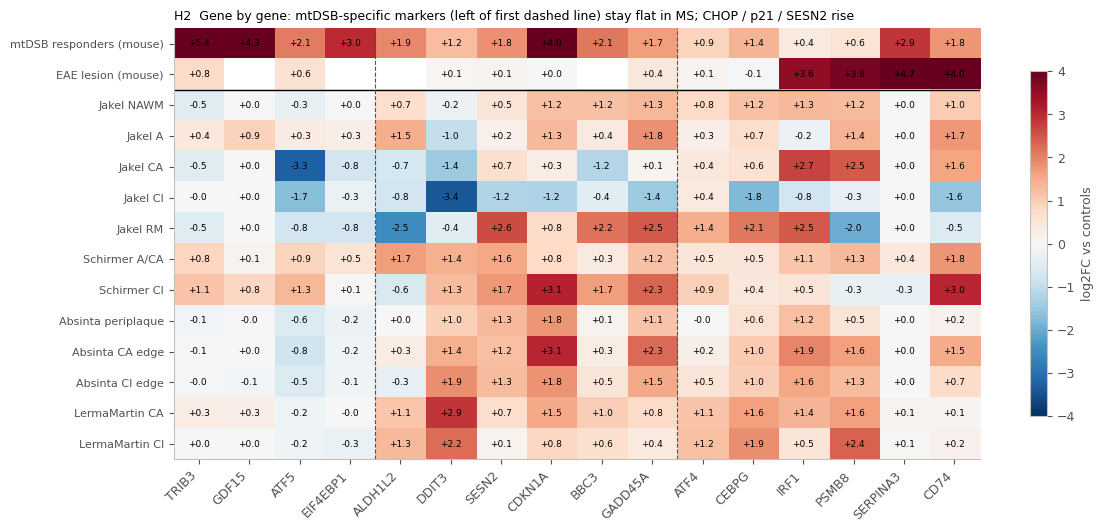

In [3]:
mt = pd.read_csv(REPO / "results" / "eae_comparison" / "tables" / "ol_log2fc_mtdsb_vs_eae.csv", index_col=0)
mt.index = [to_human([g])[0] for g in mt.index]
mt = mt[~mt.index.duplicated()]
GENES = ["TRIB3", "GDF15", "ATF5", "EIF4EBP1", "ALDH1L2", "DDIT3", "SESN2", "CDKN1A", "BBC3", "GADD45A", "ATF4", "CEBPG", "IRF1", "PSMB8", "SERPINA3", "CD74"]
gene_rows = {}
for ds, ctl in CTRL.items():
    L = sample_log_cpm(ds); Z = L - L.xs(ctl, level="lesion").mean()
    for les in LES_ORDER[ds]:
        if les in Z.index.get_level_values("lesion"):
            gene_rows[f"{ds[:-4]} {SHORT.get(les, les)}"] = Z.xs(les, level="lesion").reindex(columns=GENES).mean()
G = pd.DataFrame(gene_rows).T
# mtDSB values for genes filtered out of the analysis/10 table come from the analysis/13 pathway table (same pseudobulk)
pw = pd.read_csv(REPO / "results" / "ol_mechanism" / "tables" / "pathway_genes.csv").drop_duplicates("gene").set_index("gene").resp_log2fc
pw.index = [to_human([g])[0] for g in pw.index]
mt_ref = mt["mtDSB responders"].reindex(GENES).fillna(pw[~pw.index.duplicated()].reindex(GENES))
ref = pd.DataFrame({"mtDSB responders (mouse)": mt_ref, "EAE lesion (mouse)": mt["EAE lesion"].reindex(GENES)}).T
G = save_table(pd.concat([ref, G]).round(2), "core_genes_log2fc")
fig, ax = plt.subplots(figsize=(13, 5.6))
im = ax.imshow(G, cmap="RdBu_r", vmin=-4, vmax=4, aspect="auto")
for i in range(G.shape[0]):
    for j in range(G.shape[1]):
        v = G.iat[i, j]
        ax.text(j, i, "" if pd.isna(v) else f"{v:+.1f}", ha="center", va="center", fontsize=6.5)
ax.set_xticks(range(len(GENES)), GENES, rotation=45, ha="right"); ax.set_yticks(range(G.shape[0]), G.index, fontsize=8)
ax.axhline(1.5, color="k", lw=1); ax.axvline(3.5, color=INK2, lw=0.8, ls="--"); ax.axvline(9.5, color=INK2, lw=0.8, ls="--")
fig.colorbar(im, ax=ax, shrink=0.8, label="log2FC vs controls")
ax.set_title("H2  Gene by gene: mtDSB-specific markers (left of first dashed line) stay flat in MS; CHOP / p21 / SESN2 rise", fontsize=9)
save(fig, "H2_core_genes")
display(G)

**B.** Splitting the core set changes the picture:

* **The mtDSB-specific markers are not up in MS OLs.** TRIB3, GDF15, ATF5 and EIF4EBP1 (+2 to +5 log2 in mtDSB
  responders, ~0.6 or less in EAE) stay within about +/-0.3 log2 of controls in Absinta and Lerma-Martin (ATF5 even
  slightly down); only Schirmer shows TRIB3 / ATF5 at about +1.
* **What rises is a general stress arm shared with mtDSB**: DDIT3 (CHOP; +1.0 to +2.9 log2), CDKN1A (p21; +0.8 to
  +3.1), SESN2, GADD45A, CEBPG, ALDH1L2 (Lerma-Martin) and modestly BBC3 (PUMA). These are classic integrated-stress and
  DNA-damage / p53 genes that rise in many kinds of cellular stress.
* **Together with interferon-gamma genes** (IRF1, PSMB8 +0.5 to +2.4) as in EAE; CD74 rises in Schirmer, Absinta and
  Jäkel but not Lerma-Martin; SERPINA3 is absent or barely detected in these nuclei.

## C. Per cell: a rare population carrying the mtDSB-specific markers?

specific  chop_p21
dataset         lesion                                             
Absinta2021     MS_periplaque_white_matter           0.00      0.39
                chronic_active_MS_lesion_edge        0.00      0.50
                chronic_inactive_MS_lesion_edge      0.00      0.37
                control_white_matter                 0.02      0.00
Jakel2019       A                                    0.00      0.14
                CA                                   0.00      0.00
                CI                                   0.00      0.00
                Ctrl                                 0.20      0.10
                NAWM                                 0.13      0.18
                RM                                   0.00      0.00
LermaMartin2024 CA                                   0.09      0.21
                CI                                   0.08      0.14
                Ctrl                                 0.06      0.02
Schirmer2019    Acute/Chronic active                 1.82      0.08
                Chronic inactive                     3.98      0.74
                Control                              1.11      0.00

,n,MTDSB_CORE,ISR,P53,IFNG,IMMUNE_OL,MYELIN,% of nuclei in CA,% of nuclei in CI,% of nuclei in Ctrl
subtype,,,,,,,,,,
OL_Dis2,2085,0.431,0.815,1.484,0.405,0.816,3.368,4.937,2.086,1.266
OPC_COP,144,0.401,0.893,1.309,0.431,0.645,1.864,0.460,0.036,0.013
OPC_PreOPC,121,0.352,0.473,1.442,0.893,0.707,1.033,0.399,0.024,0.000
OL_R,33,0.346,0.767,0.686,0.215,1.566,5.187,0.031,0.144,0.000
OPC_Mature,43,0.330,0.731,1.546,0.243,0.414,4.533,0.126,0.030,0.004
OPC_Dis1,273,0.323,0.799,1.183,0.376,0.563,0.373,0.538,0.450,0.176
OPC_Dis2,1141,0.321,0.793,1.150,0.372,0.594,0.378,2.685,1.445,0.492
OPC_Stress,136,0.296,0.618,1.044,0.436,0.710,0.505,0.392,0.096,0.022
OPC_PreOL,198,0.251,0.799,1.213,0.403,0.592,2.564,0.259,0.600,0.097


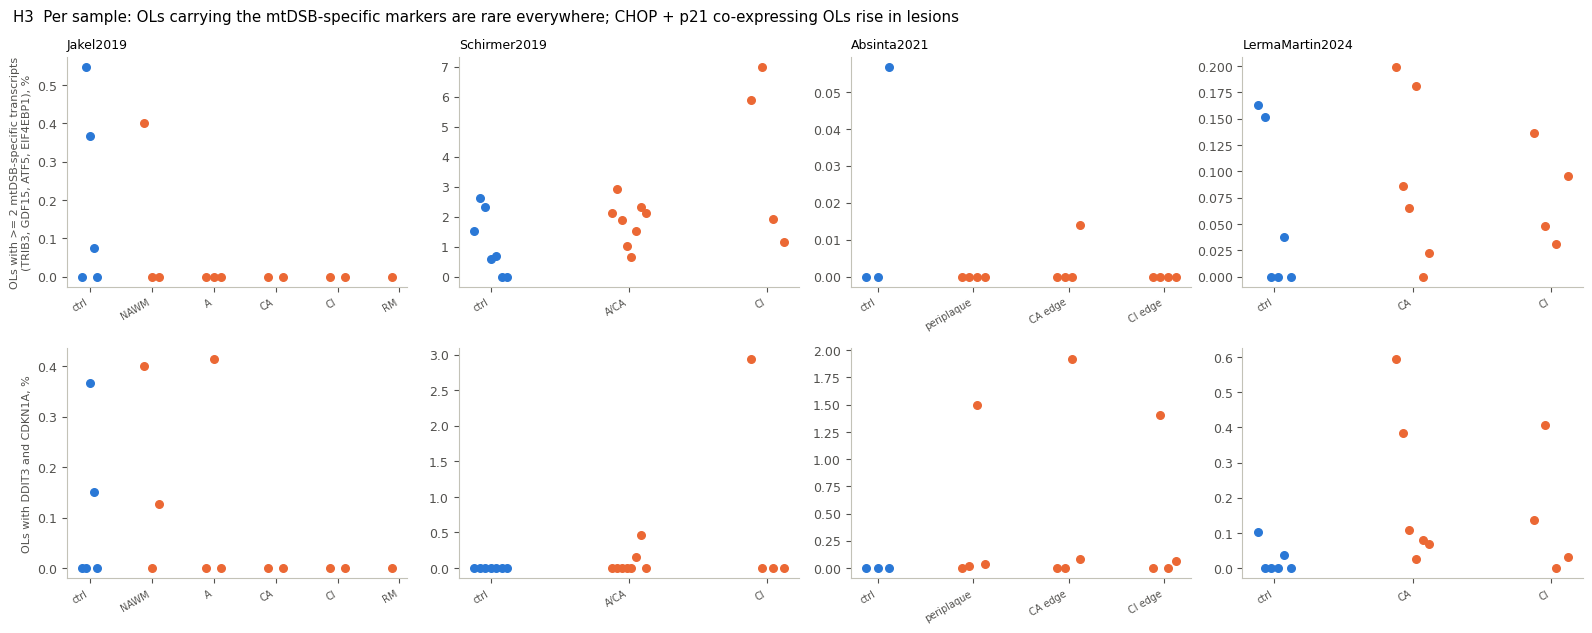

In [4]:
o = ol.copy()
o["n_specific"] = o[[g for g in SPECIFIC if g in o]].sum(1)
o["specific_pos"] = o.n_specific >= 2
o["ddit3_cdkn1a"] = (o.DDIT3 > 0) & (o.CDKN1A > 0)
frac = (o.groupby(["dataset", "lesion", "sample"]).agg(n=("specific_pos", "size"), specific=("specific_pos", "mean"), chop_p21=("ddit3_cdkn1a", "mean"),
                                                       total_counts=("total_counts", "median"))
        .reset_index())
frac = frac[frac.n >= MIN_NUCLEI]
save_table(frac.round(5), "specific_marker_fraction_per_sample", index=False)
fig, axes = plt.subplots(2, 4, figsize=(16, 6.4))
for j, (ds, ctl) in enumerate(CTRL.items()):
    d = frac[frac.dataset == ds]
    order = [ctl] + [l for l in LES_ORDER[ds] if l in set(d.lesion)]
    for i, (col, lab) in enumerate((("specific", "OLs with >= 2 mtDSB-specific transcripts\n(TRIB3, GDF15, ATF5, EIF4EBP1), %"), ("chop_p21", "OLs with DDIT3 and CDKN1A, %"))):
        ax = axes[i, j]
        for k, les in enumerate(order):
            v = 100 * d[d.lesion == les][col]
            ax.scatter(np.full(len(v), k) + np.linspace(-0.12, 0.12, len(v)), v, s=30, color=BLUE if les == ctl else ORANGE, zorder=3)
        ax.set_xticks(range(len(order)), ["ctrl"] + [SHORT.get(l, l) for l in order[1:]], rotation=30, ha="right", fontsize=7)
        ax.set_title(f"{ds}" if i == 0 else "", fontsize=9)
        if j == 0: ax.set_ylabel(lab, fontsize=8)
fig.suptitle("H3  Per sample: OLs carrying the mtDSB-specific markers are rare everywhere; CHOP + p21 co-expressing OLs rise in lesions", x=0.01, ha="left")
fig.tight_layout(); save(fig, "H3_per_cell_fractions")
display(frac.groupby(["dataset", "lesion"])[["specific", "chop_p21"]].mean().mul(100).round(2))

lm = cells[cells.dataset == "LermaMartin2024"]
sub = lm.groupby("subtype").agg(n=("MTDSB_CORE", "size"), MTDSB_CORE=("MTDSB_CORE", "mean"), ISR=("ISR", "mean"), P53=("P53", "mean"),
                                IFNG=("IFNG", "mean"), IMMUNE_OL=("IMMUNE_OL", "mean"), MYELIN=("MYELIN", "mean"))
share = pd.crosstab(lm.subtype, lm.lesion, normalize="columns").mul(100)
sub = save_table(sub.join(share.add_prefix("% of nuclei in ")).round(3), "lerma_martin_subtypes")
display(sub.sort_values("MTDSB_CORE", ascending=False))

**C.** OLs carrying two or more mtDSB-specific transcripts (TRIB3, GDF15, ATF5, EIF4EBP1) are essentially absent from
Absinta, Lerma-Martin and Jäkel (< 0.2 % of OLs, lesions and controls alike). Only Schirmer, the deepest libraries and
including cortex, detects them more often, with a modest lesion excess (1.8 % in acute / chronic active and 4.0 % in
chronic inactive vs 1.1 % in controls). In mtDSB responders, Trib3+ OLs are ~1-3 % by Xenium (analysis/13); snRNA picks
up such low-expressed genes less often, so a small population could be missed. OLs co-expressing DDIT3 and CDKN1A
rise in lesions in all three larger atlases (e.g. Absinta 0.4-0.5 % vs 0 %), matching B. Among the Lerma-Martin
OL subtypes, the disease-associated OL_Dis2 has the highest core score and is enriched in chronic active lesions
(4.9 % of OL-lineage nuclei vs 1.3 % in controls), but its score comes from the shared stress genes.

## D. Genome-wide similarity to mtDSB and EAE

,dataset,lesion,n_genes,r_mtDSB,r_EAE_lesion,r_EAE_DAO_vs_MOL
0,Jakel2019,NAWM,2286,-0.009,0.050,-0.055
1,Jakel2019,A,2286,0.044,0.133,0.133
2,Jakel2019,CA,2286,-0.004,0.088,0.065
3,Jakel2019,CI,2286,-0.044,0.040,0.039
4,Jakel2019,RM,2286,0.079,0.100,0.112
5,Schirmer2019,A/CA,2442,0.170,0.135,0.053
6,Schirmer2019,CI,2442,0.013,-0.147,-0.336
7,Absinta2021,periplaque,2156,0.117,-0.000,-0.025
8,Absinta2021,CA edge,2156,0.158,0.100,0.010
9,Absinta2021,CI edge,2156,0.149,0.101,0.013


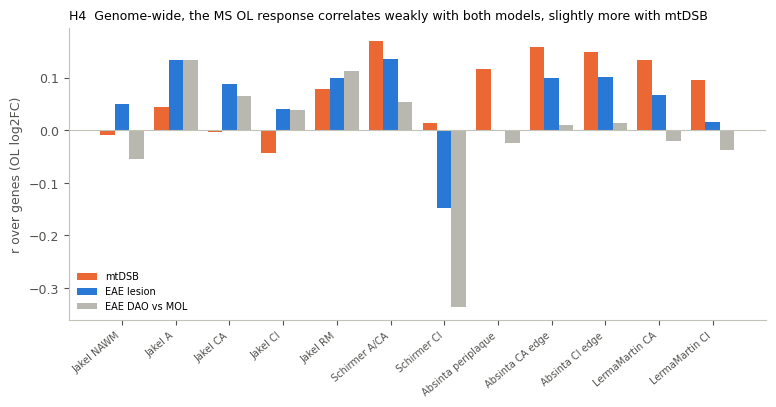

In [5]:
sim = []
for ds, ctl in CTRL.items():
    L = sample_log_cpm(ds)
    expressed = L.columns[(np.exp2(L) - 1).mean() > 5]
    Z = L[expressed] - L[expressed].xs(ctl, level="lesion").mean()
    for les in LES_ORDER[ds]:
        if les not in Z.index.get_level_values("lesion"): continue
        lfc = Z.xs(les, level="lesion").mean()
        com = lfc.index.intersection(mt.index[~mt.index.duplicated()])
        m_ = mt[~mt.index.duplicated()].loc[com]
        sim.append({"dataset": ds, "lesion": SHORT.get(les, les), "n_genes": len(com),
                    "r_mtDSB": np.corrcoef(lfc[com], m_["mtDSB responders"])[0, 1], "r_EAE_lesion": np.corrcoef(lfc[com], m_["EAE lesion"])[0, 1],
                    "r_EAE_DAO_vs_MOL": np.corrcoef(lfc[com], m_["DAO vs MOL"])[0, 1]})
sim = save_table(pd.DataFrame(sim).round(3), "similarity_to_mouse_models", index=False)
fig, ax = plt.subplots(figsize=(9, 3.8))
x = np.arange(len(sim))
for k, (col, c_) in enumerate((("r_mtDSB", ORANGE), ("r_EAE_lesion", BLUE), ("r_EAE_DAO_vs_MOL", GREY))):
    ax.bar(x + (k - 1) * 0.27, sim[col], width=0.27, color=c_, label=col.replace("r_", "").replace("_", " "))
ax.axhline(0, color=AXIS, lw=0.8); ax.set_xticks(x, [f"{d[:-4]} {l}" for d, l in zip(sim.dataset, sim.lesion)], rotation=40, ha="right", fontsize=7)
ax.set_ylabel("r over genes (OL log2FC)"); ax.legend(frameon=False, fontsize=7)
ax.set_title("H4  Genome-wide, the MS OL response correlates weakly with both models, slightly more with mtDSB", fontsize=9)
save(fig, "H4_similarity")
display(sim)

**D.** Over the ~2,100-2,400 genes measured in both species, MS lesion OL changes correlate weakly with both mouse
models, and in the three larger atlases slightly more with mtDSB (r 0.10-0.17) than with EAE lesion OLs (r 0.00-0.14)
or the EAE DAO state (about 0). The overlap with mtDSB is the shared CHOP / p21 stress arm; the EAE-like part is the
interferon-gamma programme. All correlations are modest (species, technology, tissue, time point).

## Summary

* **The mtDSB-specific fingerprint is not found in human MS oligodendrocytes**: TRIB3, GDF15, ATF5 and EIF4EBP1, the
  markers that separate mtDSB from EAE, are not raised in MS lesion OLs in Absinta and Lerma-Martin, and only modestly
  in Schirmer; OLs carrying them are rare.
* **MS OLs share the general stress arm with mtDSB**: DDIT3 (CHOP), CDKN1A (p21), SESN2, GADD45A and CEBPG rise in
  lesion and periplaque OLs, alongside the interferon-gamma / immune-visible programme typical of EAE. Genome-wide the
  MS OL response correlates weakly with both models, slightly more with mtDSB.
* So MS OLs look like **inflammation-exposed OLs with a CHOP / p21 stress component**, not like OLs with primary mtDNA
  damage. TRIB3 / GDF15 / ATF5 remain the candidates for a marker panel of mtDNA-damage OLs; in these MS samples
  that state is rare or absent, at least at snRNA depth.
* Caveats: snRNA depth and nuclear-only transcripts (low-expressed TRIB3 / GDF15 are hard to detect), post-mortem
  tissue, mostly chronic lesions, few samples per lesion type. The human CNS Xenium 5k run on the office Mac
  (`/Volumes/moldiassd/human_ms_xenium`, `human_MS_Balo`) could test the markers in situ with the same technology as
  the mouse data.